> Versión de portafolio. Se conservan las salidas históricas del trabajo académico. Las rutas absolutas de datos, cuando existían, se sustituyeron por nombres locales. Esta versión no se ha ejecutado de nuevo; consulte README y DATOS.md antes de reproducir.


# Módulo 55 | Pronóstico AR(p) de DIS
**Periodo de estimación:** 3 de enero a 31 de marzo de 2023. **Horizonte:** sesiones de abril de 2023.  
Fuente: [Yahoo Finance, histórico DIS](https://finance.yahoo.com/quote/DIS/history/). Serie: **Close**, precio de cierre en USD; se congela una copia CSV junto al notebook. Fecha de consulta: 28 de septiembre de 2026. Este ejercicio retrospectivo no constituye una recomendación de inversión.

## 1. Diseño y prevención de fuga de datos
El 1 de enero no hubo cotización. Las primeras 70% observaciones cronológicas forman entrenamiento; las restantes 30% se reservan para prueba. Se calcula la PACF y se selecciona el orden únicamente en entrenamiento. AIC/BIC se comparan con `hold_back` común, porque cada AR(p) ordinario elimina un número diferente de observaciones. Se elige el menor BIC comparable y se presenta AIC como contraste. El pronóstico de prueba nace del último día de entrenamiento y avanza sin usar observaciones posteriores. Tras la validación se reestima el mismo orden con todo enero-marzo y se pronostica abril.

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error
df = pd.read_csv('DIS_Yahoo_2023_enero_abril.csv', parse_dates=['fecha']).set_index('fecha')
q = df.loc['2023-01-01':'2023-03-31','cierre_usd']
abril = df.loc['2023-04-01':'2023-04-30','cierre_usd']
n = len(q); k = int(np.floor(.70*n)); train, test = q.iloc[:k], q.iloc[k:]
print(f'Total: {n}; entrenamiento: {len(train)}, hasta {train.index[-1].date()}; prueba: {len(test)}, desde {test.index[0].date()}; abril: {len(abril)}')

Total: 62; entrenamiento: 43, hasta 2023-03-06; prueba: 19, desde 2023-03-07; abril: 19


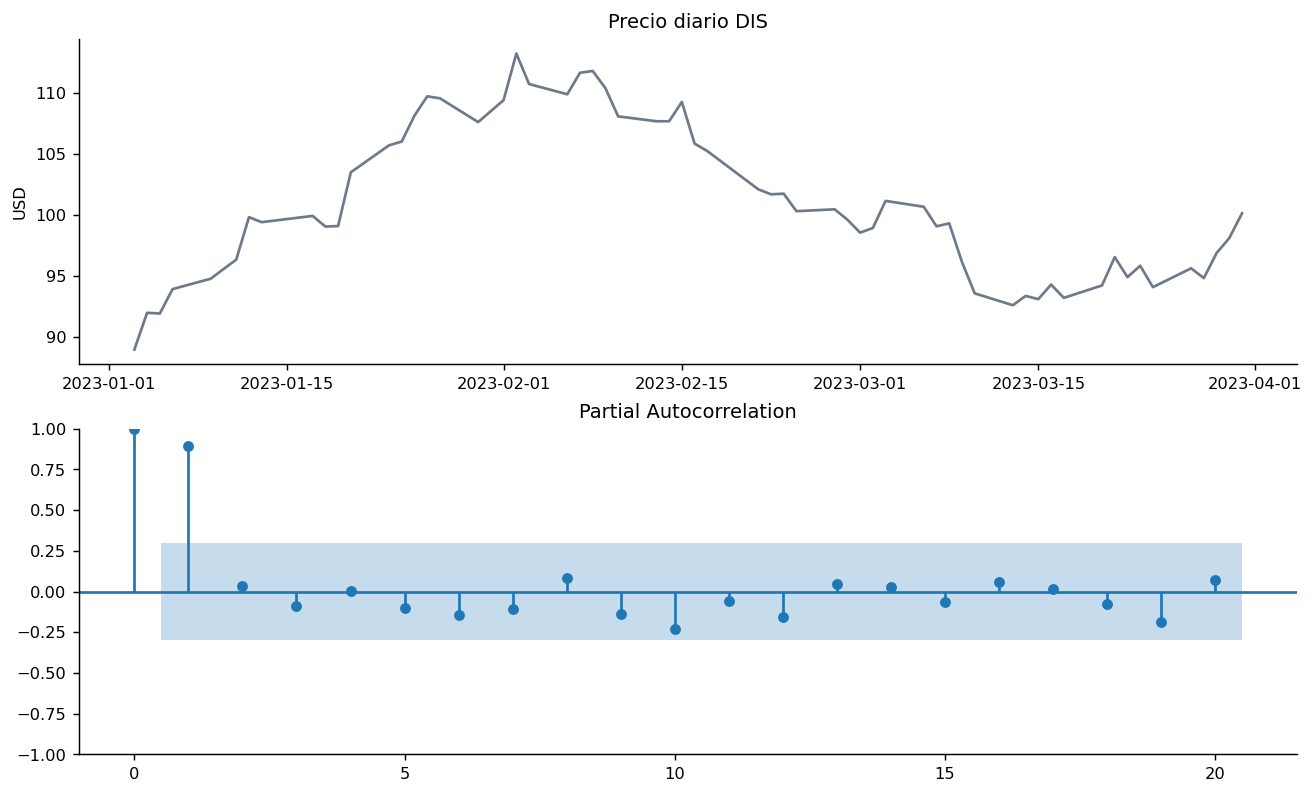

In [ ]:
fig, ax = plt.subplots(2,1,figsize=(10,6),layout='constrained')
ax[0].plot(q.index,q,color='#6E7A89'); ax[0].set(title='Precio diario DIS',ylabel='USD')
plot_pacf(train,lags=min(20,len(train)//2-1),method='ywm',ax=ax[1]); plt.show()

## 2. Selección del orden
La PACF sirve como orientación visual. La decisión cuantitativa se apoya en BIC con igual número de observaciones efectivas. El diagnóstico ADF advierte si modelar niveles como un AR estacionario resulta dudoso; un AR(p) puede arrojar una buena apariencia de ajuste dentro de muestra sin capacidad de pronóstico.

 p        AIC        BIC  n_efectiva
 1 141.875041 146.541085          35
 2 143.426611 149.648003          35
 3 145.426082 153.202823          35
 4 147.413891 156.745979          35
 5 147.068888 157.956324          35
 6 145.890364 158.333149          35
 7 147.461555 161.459688          35
 8 149.460990 165.014470          35
Orden seleccionado: 1
ADF entrenamiento: p= 0.030512547943541392


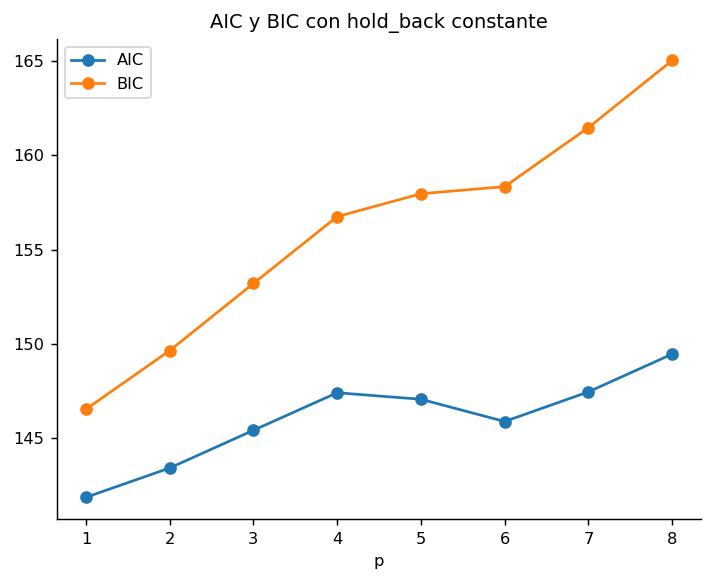

In [ ]:
pmax=min(10,len(train)//5)
comparables={p:AutoReg(train.to_numpy(),lags=p,trend='c',hold_back=pmax).fit() for p in range(1,pmax+1)}
seleccion=pd.DataFrame([{'p':p,'AIC':m.aic,'BIC':m.bic,'n_efectiva':m.nobs} for p,m in comparables.items()])
p=int(seleccion.sort_values(['BIC','p']).iloc[0].p)
print(seleccion.to_string(index=False)); print('Orden seleccionado:',p)
print('ADF entrenamiento: p=',adfuller(train,autolag='AIC')[1])
seleccion.set_index('p')[['AIC','BIC']].plot(marker='o',title='AIC y BIC con hold_back constante');plt.show()

## 3. Validación cronológica
Se evalúan pronósticos de múltiples pasos emitidos en un único origen temporal. Esto reproduce el problema de abril y es más exigente que un paso adelante alimentado cada día con el dato real. El comparador ingenuo conserva el último cierre de entrenamiento en todos los pasos.

          AR(p)  Ingenuo
MAE       8.239    5.095
RMSE      8.622    5.552
MAPE (%)  8.679    5.387
Ljung-Box residuos:     lb_stat  lb_pvalue
8   7.1166     0.5241


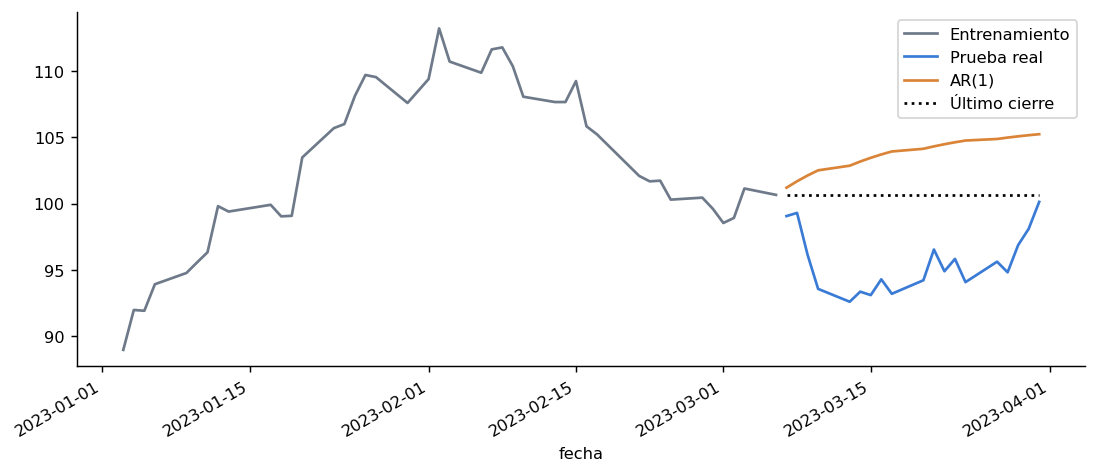

In [ ]:
modelo=AutoReg(train.to_numpy(),lags=p,trend='c').fit()
pron_prueba=np.asarray(modelo.forecast(steps=len(test)))
ingenuo=np.repeat(train.iloc[-1],len(test))
def evaluar(y,pred):
    y=np.asarray(y); pred=np.asarray(pred)
    return {'MAE':mean_absolute_error(y,pred),'RMSE':np.sqrt(mean_squared_error(y,pred)),
            'MAPE (%)':100*np.mean(np.abs((y-pred)/y))}
print(pd.DataFrame({'AR(p)':evaluar(test,pron_prueba),'Ingenuo':evaluar(test,ingenuo)}).round(3))
print('Ljung-Box residuos: ',acorr_ljungbox(modelo.resid,lags=[min(8,len(modelo.resid)//5)],return_df=True).round(4))
ax=train.plot(figsize=(10,4),label='Entrenamiento',color='#6E7A89');test.plot(ax=ax,label='Prueba real',color='#3A7BD5')
ax.plot(test.index,pron_prueba,label=f'AR({p})',color='#DA8437');ax.plot(test.index,ingenuo,':',label='Último cierre',color='black');ax.legend();plt.show()

## 4. Pronóstico de abril de 2023
La lista de sesiones de abril procede de las fechas efectivamente negociadas conservadas en la fuente; **solo las fechas**, y no los precios de abril, intervienen antes de emitir el pronóstico. El intervalo de confianza solicitado es, para un valor futuro, técnicamente un **intervalo de predicción** del 90%, condicional a los supuestos del modelo. El resultado se emitió conceptualmente al cierre del 31 de marzo.

     Fecha  Pronóstico USD  Límite inferior 90%  Límite superior 90%
2023-04-03          100.36                97.63               103.09
2023-04-04          100.57                96.84               104.30
2023-04-05          100.77                96.35               105.20
2023-04-06          100.96                96.01               105.91
2023-04-10          101.13                95.76               106.50
2023-04-11          101.30                95.59               107.01
2023-04-12          101.45                95.46               107.44
2023-04-13          101.59                95.36               107.82
2023-04-14          101.72                95.30               108.15
2023-04-17          101.85                95.26               108.44
2023-04-18          101.96                95.23               108.70
2023-04-19          102.07                95.21               108.93
2023-04-20          102.17                95.21               109.14
2023-04-21          102.27        

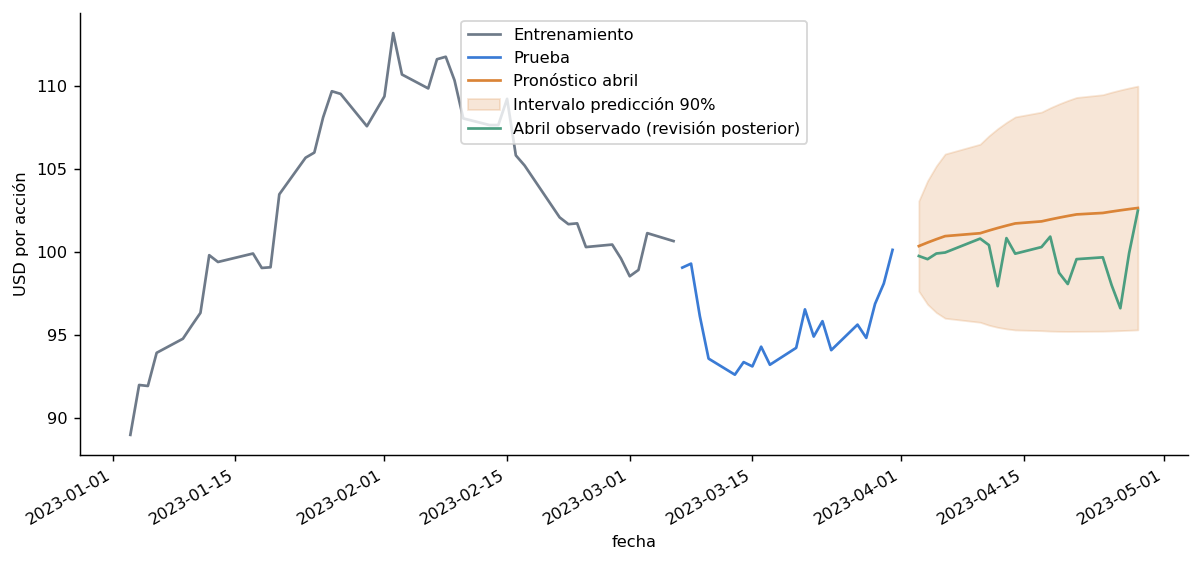

In [ ]:
final=AutoReg(q.to_numpy(),lags=p,trend='c').fit()
fut=final.get_prediction(start=len(q),end=len(q)+len(abril)-1)
ci=np.asarray(fut.conf_int(alpha=.10)); estim=np.asarray(fut.predicted_mean)
tabla=pd.DataFrame({'Fecha':abril.index,'Pronóstico USD':estim,'Límite inferior 90%':ci[:,0],'Límite superior 90%':ci[:,1]})
print(tabla.round(2).to_string(index=False))
ax=train.plot(figsize=(11,5),color='#6E7A89',label='Entrenamiento');test.plot(ax=ax,color='#3A7BD5',label='Prueba')
ax.plot(abril.index,estim,color='#DA8437',label='Pronóstico abril')
ax.fill_between(abril.index,ci[:,0],ci[:,1],color='#DA8437',alpha=.2,label='Intervalo predicción 90%')
ax.plot(abril.index,abril,color='#4B9E80',label='Abril observado (revisión posterior)')
ax.legend();ax.set_ylabel('USD por acción');plt.show()

## 5. Exactitud y criterio de negocio
Primero se juzga la aptitud prospectiva con errores sobre el bloque de prueba y se compara con el pronóstico ingenuo. La amplitud creciente de intervalos muestra pérdida de precisión con el horizonte. Dado que abril ya ocurrió, se añaden métricas posteriores de abril **sin usarlas para elegir p o modificar el modelo**; esto permite comprobar la cobertura empírica, aunque una sola ventana y una muestra pequeña no garantizan desempeño futuro. Los precios bursátiles pueden reaccionar a noticias que un AR(p) univariado no ve.

In [ ]:
cubierto=((abril.to_numpy()>=ci[:,0])&(abril.to_numpy()<=ci[:,1])).mean()
print('Prueba AR:',evaluar(test,pron_prueba));print('Prueba ingenuo:',evaluar(test,ingenuo))
print('Abril retrospectivo:',evaluar(abril,estim));print('Cobertura abril del intervalo 90%:',f'{100*cubierto:.1f}%')
print('p seleccionado:',p,'| cierre marzo:',round(q.iloc[-1],2),'| primer pronóstico:',round(estim[0],2))

Prueba AR: {'MAE': 8.239213497294092, 'RMSE': np.float64(8.622183264336952), 'MAPE (%)': np.float64(8.679234659319938)}
Prueba ingenuo: {'MAE': 5.095266947368423, 'RMSE': np.float64(5.552150992848346), 'MAPE (%)': np.float64(5.387101840458645)}
Abril retrospectivo: {'MAE': 2.067281130954104, 'RMSE': np.float64(2.591332367448083), 'MAPE (%)': np.float64(2.093288128298727)}
Cobertura abril del intervalo 90%: 100.0%
p seleccionado: 1 | cierre marzo: 100.13 | primer pronóstico: 100.36


## Conclusión
La selección parsimoniosa requiere PACF, AIC y BIC, pero la aptitud para pronosticar se juzga en el tramo cronológico apartado y frente a un punto de referencia sencillo. El modelo AR(p) en niveles se interpreta con cautela cuando ADF no respalda estacionariedad. Se evita equiparar una métrica de ajuste o un intervalo nominal del modelo con certeza de precio futuro. Para mejorar el método se puede ampliar el historial, comparar ARIMA sobre diferencias y validar en múltiples ventanas móviles.